FIAP

# TIAO - Redes Neurais - Aula 1

# Aula 1 - Perceptron & Redes Neurais Multicamadas

Vamos utilizar o [Iris dataset](https://archive.ics.uci.edu/ml/datasets/iris) para modelar Redes Neruais baseadas no Perceptron e em MLPClassifier.

Como se trata de um dataset MUITO famoso em Ciência de Dados, o próprio sklearn já possui os dados salvos

In [1]:
# Apenas para evitar warnings
import warnings
warnings.filterwarnings('ignore')

# Bibliotecas de Data Science
import pandas as pd
import seaborn as sns

# Separação dos dados
from sklearn.model_selection import train_test_split

# Modelos a serem utilizados
from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPClassifier

# Métricas de avaliação
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score



# Lendo o montando o DataFrame com o dataset
from sklearn.datasets import load_iris
iris = load_iris()

# Transformando em Dataframe Pandas:
#   - os dados são iris.data
#   - as colunas são os nomes das características
data = pd.DataFrame( iris.data, columns=iris.feature_names )
data["class"] = iris.target
data

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),class
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


## Dividindo os dados em TREINO e TESTE

In [2]:
X = data.drop(columns=["class"]) # variáveis
y = data["class"]                # label

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

## Perceptron

Vamos começar trabalhando com uma rede bem básica: o Perceptron

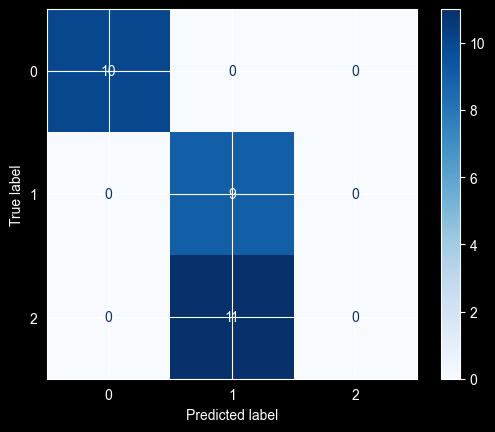

In [3]:
# Cria um perceptron e o treina (com o fit())
p = Perceptron( random_state=42 )
p.fit(X_train, y_train)

# Salva as predições do TESTE na variável y_pred
y_pred = p.predict(X_test)

# Matriz de confusão do perceptron
from sklearn.metrics import confusion_matrix

def matriz_confusao(teste_labels, teste_preds, labels):
  cm = confusion_matrix(teste_labels, teste_preds, labels=labels)
  disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                display_labels=labels)
  disp.plot(cmap="Blues")

matriz_confusao(y_test, y_pred, p.classes_)

## Uma análise do resultado do Perceptron

Resultado não foi muito bom ne? Mas faz sentido porque esse tipo de rede resolve bem problemas LINEARMENTE SEPARÁVEIS. Será que é o caso deste dataset?

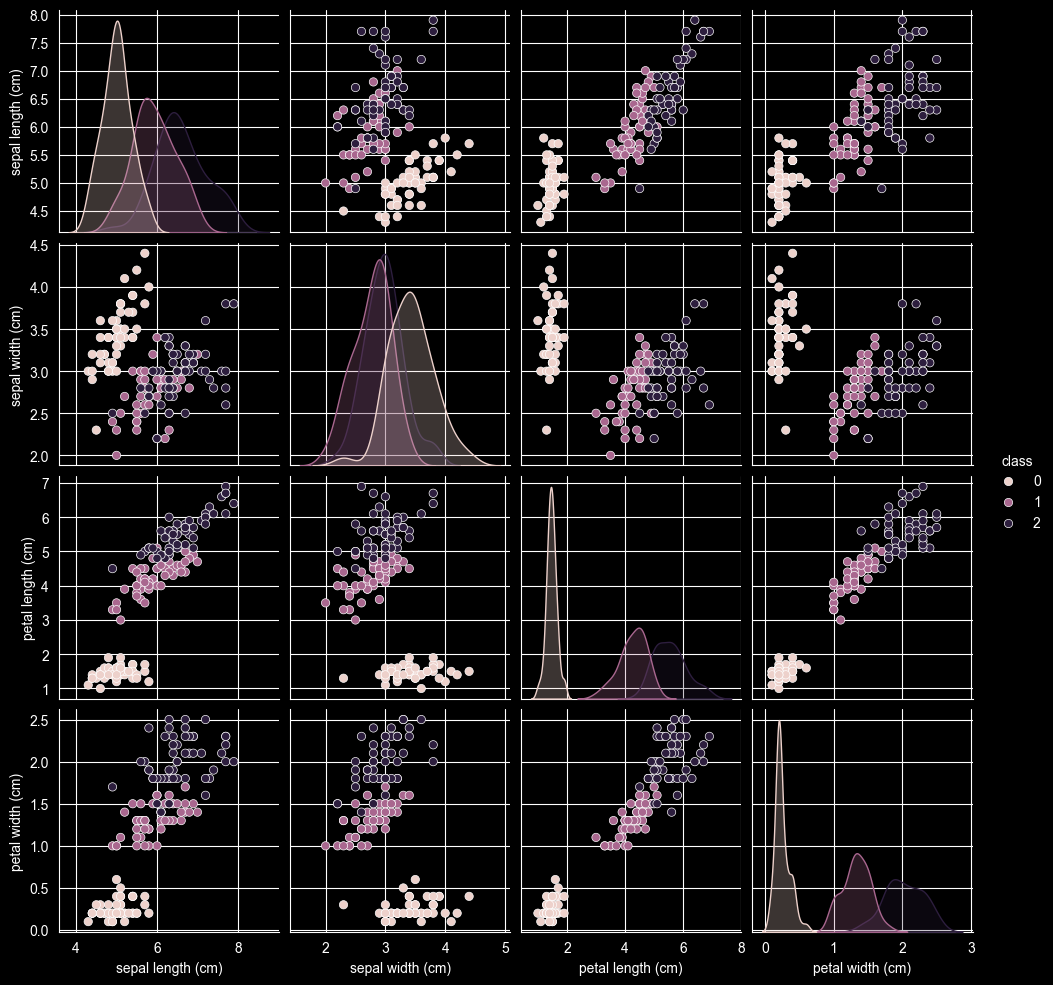

In [4]:
sns.pairplot( data=data, vars=('sepal length (cm)', \
                               'sepal width (cm)', \
                               'petal length (cm)', \
                               'petal width (cm)'), \
             hue='class' );

## Multi-layer Perceptron (MLP)

Veja [aqui](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html#sklearn.neural_network.MLPClassifier) todos os parâmetros e seus significados.

Vamos começar com a arquitetura mais simples:

![Arquitetura inicial](https://miro.medium.com/max/381/1*Pff-9bCGTqE6iMW2sBSTmw.png)

Iteration 1, loss = 2.08037493
Iteration 2, loss = 2.06532354
Iteration 3, loss = 2.05033268
Iteration 4, loss = 2.03525767
Iteration 5, loss = 2.02015639
Iteration 6, loss = 2.00505941
Iteration 7, loss = 1.99005943
Iteration 8, loss = 1.97508232
Iteration 9, loss = 1.96009013
Iteration 10, loss = 1.94520369
Iteration 11, loss = 1.93042694
Iteration 12, loss = 1.91568140
Iteration 13, loss = 1.90103579
Iteration 14, loss = 1.88631849
Iteration 15, loss = 1.87144170
Iteration 16, loss = 1.85650081
Iteration 17, loss = 1.84135841
Iteration 18, loss = 1.82623030
Iteration 19, loss = 1.81102525
Iteration 20, loss = 1.79576661
Iteration 21, loss = 1.78057518
Iteration 22, loss = 1.76543617
Iteration 23, loss = 1.75043564
Iteration 24, loss = 1.73557174
Iteration 25, loss = 1.72086287
Iteration 26, loss = 1.70630537
Iteration 27, loss = 1.69190475
Iteration 28, loss = 1.67767132
Iteration 29, loss = 1.66362040
Iteration 30, loss = 1.64973531
Iteration 31, loss = 1.63601784
Iteration 32, los

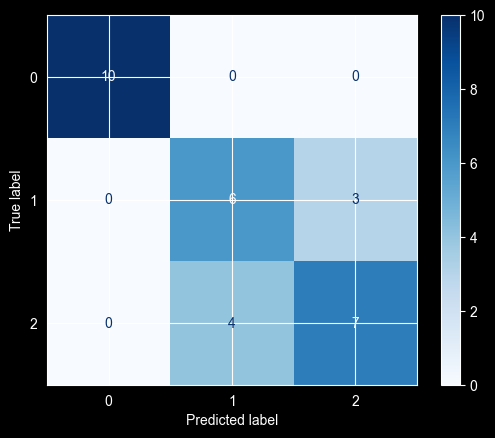

In [5]:
#Arquitetura
mlp = MLPClassifier(
    hidden_layer_sizes=(5,),
    verbose=True,
    max_iter=200,
    random_state=1
)

# Treinamento
mlp.fit(X_train, y_train)
y_pred = mlp.predict(X_test)

# Avaliação
matriz_confusao(y_test, y_pred, mlp.classes_)

### Ajustando parâmetros...

Comparando os diferentes resultados alcançados com a alteração de parâmetros, fica clara (mais uma vez) a **importância de ajustar esses parâmetros**.

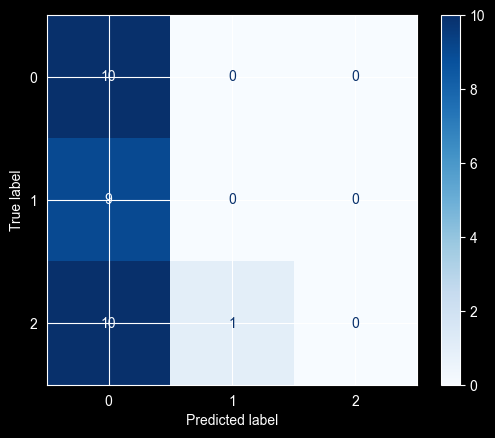

In [6]:
#Alterando a função de ativação...
mlp = MLPClassifier(
    hidden_layer_sizes=(5,),
    verbose=False,
    max_iter=50,
    random_state=1,
    activation="logistic"
)

mlp.fit(X_train, y_train)
y_pred = mlp.predict(X_test)

matriz_confusao(y_test, y_pred, mlp.classes_)

ACC Teste:  1.0


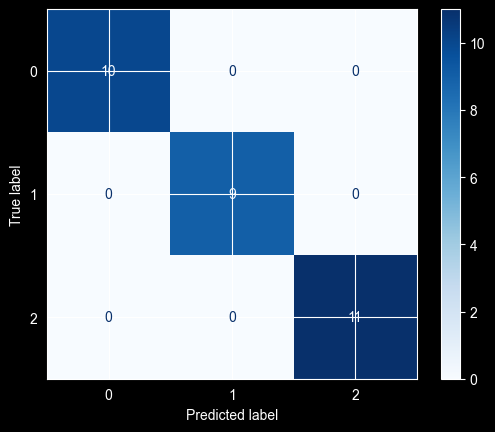

In [7]:
#Alterando o solver para o que a própria documentação aconselha para datasets menores
mlp = MLPClassifier(
    hidden_layer_sizes=(5,),
    verbose=False,
    max_iter=50,
    random_state=1,
    activation="logistic",
    solver="lbfgs"
)

mlp.fit(X_train, y_train)
y_pred = mlp.predict(X_test)

print("ACC Teste: ", accuracy_score(y_test, y_pred))

matriz_confusao(y_test, y_pred, mlp.classes_)

Iteration 1, loss = 1.17696538
Iteration 2, loss = 1.17591871
Iteration 3, loss = 1.17487912
Iteration 4, loss = 1.17384675
Iteration 5, loss = 1.17282172
Iteration 6, loss = 1.17180414
Iteration 7, loss = 1.17079412
Iteration 8, loss = 1.16979176
Iteration 9, loss = 1.16879718
Iteration 10, loss = 1.16781045
Iteration 11, loss = 1.16683167
Iteration 12, loss = 1.16586092
Iteration 13, loss = 1.16489828
Iteration 14, loss = 1.16394380
Iteration 15, loss = 1.16299756
Iteration 16, loss = 1.16205961
Iteration 17, loss = 1.16113000
Iteration 18, loss = 1.16020876
Iteration 19, loss = 1.15929594
Iteration 20, loss = 1.15839157
Iteration 21, loss = 1.15749565
Iteration 22, loss = 1.15660822
Iteration 23, loss = 1.15572927
Iteration 24, loss = 1.15485881
Iteration 25, loss = 1.15399683
Iteration 26, loss = 1.15314333
Iteration 27, loss = 1.15229828
Iteration 28, loss = 1.15146166
Iteration 29, loss = 1.15063344
Iteration 30, loss = 1.14981360
Iteration 31, loss = 1.14900209
Iteration 32, los

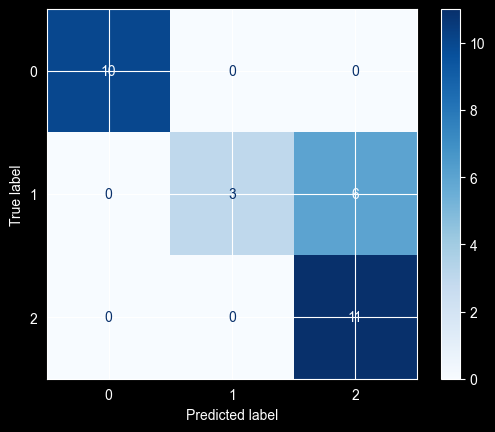

In [8]:
#Testando outra arquitetura...
mlp = MLPClassifier(
    hidden_layer_sizes=(5,3),
    verbose=True,
    max_iter=1000,
    random_state=1,
    activation="logistic",
    learning_rate="adaptive",
    solver="adam"
)

mlp.fit(X_train, y_train)
y_pred = mlp.predict(X_test)

print("ACC Teste: ", accuracy_score(y_test, y_pred))

matriz_confusao(y_test, y_pred, mlp.classes_)

ACC Teste:  0.9666666666666667


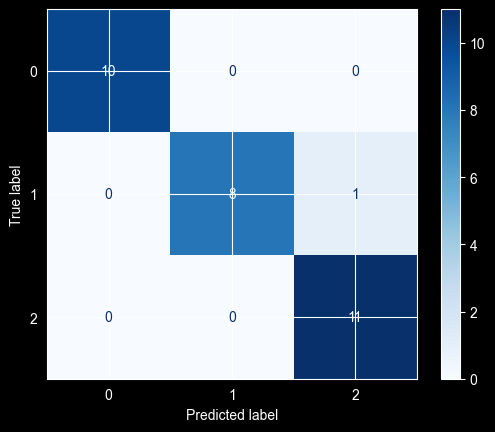

In [9]:
# Modelo com múltiplas camadas
mlp = MLPClassifier(
    hidden_layer_sizes=(5,3),
    solver="lbfgs"
)

mlp.fit(X_train, y_train)
y_pred = mlp.predict(X_test)

print("ACC Teste: ", accuracy_score(y_test, y_pred))

matriz_confusao(y_test, y_pred, mlp.classes_)

### Pesos da rede

In [10]:
print("pesos entre a camada de ENTRADA (4 neurônios) e a 1ª CAMADA OCULTA (5 neurônios):")
print(mlp.coefs_[0])
print("\npesos entre 1ª CAMADA OCULTA (5 neurônios) e a 2ª CAMADA OCULTA (3 neurônios):")
print(mlp.coefs_[1])
print("\npesos entre 2ª CAMADA OCULTA (3 neurônios) e camada de SAÍDA (3 neurônios):")
print(mlp.coefs_[2])

pesos entre a camada de ENTRADA (4 neurônios) e a 1ª CAMADA OCULTA (5 neurônios):
[[ 7.42977259 -0.29420068 -9.07608992 -0.68533651 -0.42104296]
 [ 6.2470371  -0.49179583 -5.62284051  0.54555652 -4.15496703]
 [ 0.70921636  0.25522031 -3.32966819 -0.36353358  7.55871963]
 [-0.81504035  0.08759566  0.41329069 -0.76012659  3.70686864]]

pesos entre 1ª CAMADA OCULTA (5 neurônios) e a 2ª CAMADA OCULTA (3 neurônios):
[[-0.60863094  0.92081988 -4.2323302 ]
 [-0.25154299  0.01631637 -0.31012736]
 [-0.37430749  7.66957901 -4.24938353]
 [ 0.86298324  0.20313461 -0.29168588]
 [ 0.03255979 -2.26463082 -6.37601299]]

pesos entre 2ª CAMADA OCULTA (3 neurônios) e camada de SAÍDA (3 neurônios):
[[-0.24557085 -0.35767453 -0.98179502]
 [ 1.91541345  1.42198519 -3.99588594]
 [ 3.53635807  4.39196046 -7.39165169]]


## Redes Neurais Multicamadas para Regressão

In [11]:
# Ignorar warnings
import warnings
warnings.filterwarnings("ignore")

# Bibliotecas para uso e visualização de dados
import numpy as np
import pandas as pd

# Imports para seleção de modelos
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV

# Imports para preparação de dados
from sklearn.preprocessing import StandardScaler

# Import de modelos preditivos
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor

# Import de métricas
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def metricas(X_tr_scaled, y_tr, y_ts, y_pr, model, id_modelo):

  y_pr_tr = model.predict(X_tr_scaled)

  # Erro quadrático médio
  print(f"MSE do TREINO ({id_modelo}): ", mean_squared_error(y_tr, y_pr_tr))
  print(f"MSE do TESTE  ({id_modelo}): ", mean_squared_error(y_ts, y_pr))

  # Erro absoluto médio
  print(f"MAE do TREINO ({id_modelo}): ", mean_absolute_error(y_tr, y_pr_tr))
  print(f"MAE do TESTE  ({id_modelo}): ", mean_absolute_error(y_ts, y_pr))

  # R²
  print(f"R² do TREINO ({id_modelo}): ", r2_score(y_tr, y_pr_tr))
  print(f"R² do TESTE  ({id_modelo}): ", r2_score(y_ts, y_pr))

In [12]:
# Lendo o dataset
df = pd.read_csv("advertising.csv")
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


Separação de treino e teste.

In [13]:
# Separação de DADOS e LABEL
X = df.drop(columns=["Sales"])
y = df["Sales"]

# Dividindo dados para TREINO e TESTE
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42
)

# Padronização dos dados
ss = StandardScaler()
X_train_scaled = ss.fit_transform(X_train)
X_test_scaled = ss.transform(X_test)

Modelo baseline

In [14]:
# Treinando o modelo
modelo = LinearRegression()
modelo.fit(X_train_scaled, y_train)

# Fazendo as predições
y_pred = modelo.predict(X_test_scaled)

# Metricas para regressao linear
metricas(X_train_scaled, y_train, y_test, y_pred, modelo, "Reg Linear")

MSE do TREINO (Reg Linear):  2.839232660754425
MSE do TESTE  (Reg Linear):  2.5416240362291496
MAE do TREINO (Reg Linear):  1.283630122378441
MAE do TESTE  (Reg Linear):  1.1594875061090584
R² do TREINO (Reg Linear):  0.8919647339302077
R² do TESTE  (Reg Linear):  0.9091484341849799


RNA básica

In [15]:
# Treinando uma RNA padrão e realizando predições
modelo_rn = MLPRegressor(max_iter=1000, random_state=97)
modelo_rn.fit(X_train_scaled, y_train)
y_pred_rn = modelo_rn.predict(X_test_scaled)

# Metricas para RNA otimizada
metricas(X_train_scaled, y_train, y_test, y_pred_rn, modelo_rn, "RN")

MSE do TREINO (RN):  3.3393236244781193
MSE do TESTE  (RN):  5.636869802488712
MAE do TREINO (RN):  1.381398811609204
MAE do TESTE  (RN):  1.6621776019409256
R² do TREINO (RN):  0.8729358388798696
R² do TESTE  (RN):  0.7985073950546592


RNA mais sofisticada

In [16]:
# Treinando uma RNA padrão e realizando predições
modelo_otimizado = MLPRegressor(hidden_layer_sizes=(10, 5,),
                         max_iter=1000,
                         solver="lbfgs",
                         learning_rate="adaptive",
                         random_state=97)
modelo_otimizado.fit(X_train_scaled, y_train)
y_pred_rn = modelo_otimizado.predict(X_test_scaled)

# Metricas para RNA otimizada
metricas(X_train_scaled, y_train, y_test, y_pred_rn, modelo_otimizado, "RN OTIMIZADO")

MSE do TREINO (RN OTIMIZADO):  0.416890219412159
MSE do TESTE  (RN OTIMIZADO):  1.7093292583682993
MAE do TREINO (RN OTIMIZADO):  0.44588003831829903
MAE do TESTE  (RN OTIMIZADO):  0.9404770719263541
R² do TREINO (RN OTIMIZADO):  0.9841369654559696
R² do TESTE  (RN OTIMIZADO):  0.9388992087725968


In [17]:
# Treinando uma RNA padrão e realizando predições
modelo_otimizado = MLPRegressor(hidden_layer_sizes=(10, 5,),
                         max_iter=1000,
                         solver="lbfgs",
                         learning_rate="adaptive",
                         random_state=93)
modelo_otimizado.fit(X_train_scaled, y_train)
y_pred_rn = modelo_otimizado.predict(X_test_scaled)

# Metricas para RNA otimizada
metricas(X_train_scaled, y_train, y_test, y_pred_rn, modelo_otimizado, "RN OTIMIZADO")

MSE do TREINO (RN OTIMIZADO):  0.7200084995691076
MSE do TESTE  (RN OTIMIZADO):  3.9950102622093273
MAE do TREINO (RN OTIMIZADO):  0.5661463295150656
MAE do TESTE  (RN OTIMIZADO):  1.4903576670098275
R² do TREINO (RN OTIMIZADO):  0.9726030519095284
R² do TESTE  (RN OTIMIZADO):  0.857196448965252


In [18]:
# Treinando uma RNA padrão e realizando predições
modelo_otimizado = MLPRegressor(hidden_layer_sizes=(10, 5,),
                         max_iter=1000,
                         solver="lbfgs",
                         learning_rate="adaptive",
                         random_state=3)
modelo_otimizado.fit(X_train_scaled, y_train)
y_pred_rn = modelo_otimizado.predict(X_test_scaled)

# Metricas para RNA otimizada
metricas(X_train_scaled, y_train, y_test, y_pred_rn, modelo_otimizado, "RN OTIMIZADO")

MSE do TREINO (RN OTIMIZADO):  0.6866201962754236
MSE do TESTE  (RN OTIMIZADO):  3.4227448909454243
MAE do TREINO (RN OTIMIZADO):  0.6082718452695226
MAE do TESTE  (RN OTIMIZADO):  1.4173919572056197
R² do TREINO (RN OTIMIZADO):  0.9738735058176606
R² do TESTE  (RN OTIMIZADO):  0.8776523481462244


In [19]:
# Otimização de hiperparâmetros para melhorar o resultado da predição via  MLPRegressor

# Parâmetros a serem experimentados
parameters = {
    'hidden_layer_sizes': [(5,), (10,), (10, 5,), (20, 10,)],
    'activation': ['relu', 'logistic', 'tanh'],
    'solver': ['adam', 'lbfgs'],
    'alpha': [0.0001, 0.05],
    'learning_rate': ['constant', 'adaptive'],
}

# Construção e treino do grid
clf = GridSearchCV(modelo_rn, parameters, cv=5,
                   refit=True, return_train_score=True)
clf.fit(X_train_scaled, y_train)

# Melhor modelo encontrado
print("Melhores parâmetros:")
print(clf.best_params_)

# Avaliação do melhor modelo encontrado
modelo_rn_otimizado = clf.best_estimator_
y_pred_rn_otimizado = modelo_rn_otimizado.predict(X_test_scaled)
metricas(X_train_scaled, y_train, y_test,
         y_pred_rn_otimizado, modelo_rn_otimizado, "RN OTIMIZADO")

Melhores parâmetros:
{'activation': 'relu', 'alpha': 0.05, 'hidden_layer_sizes': (10, 5), 'learning_rate': 'constant', 'solver': 'lbfgs'}
MSE do TREINO (RN OTIMIZADO):  0.38393746805698004
MSE do TESTE  (RN OTIMIZADO):  2.9127294842417792
MAE do TREINO (RN OTIMIZADO):  0.4515749508970715
MAE do TESTE  (RN OTIMIZADO):  1.1526778798644137
R² do TREINO (RN OTIMIZADO):  0.9853908462349553
R² do TESTE  (RN OTIMIZADO):  0.895883092594784
